# 2. EDA — Impression analysis: slates, clicks, position, feedback semantics and slate composition

**BT4222 Group 6 · final project · task 3 (exploratory data analysis), notebook 1 of 3.** Owner: Member 3 (Anh Minh Hoang).
Slate-composition analyses (section 6) follow Lee Yong Rui's interim notebook.

This notebook describes the impression log at the level the models operate on: the **slate** (one impression), the **candidate article**
and the **click**. It answers five questions and turns each answer into a modelling decision:

| # | Question | Decision it feeds |
|---|---|---|
| 1 | How long are slates, and how many clicks does a slate contain? | why CTR is click-conditioned, why `slate_len` is not a feature, why evaluation is per impression |
| 2 | Does the position of a candidate in the list carry information? | whether `position` is a feature and whether position bias must be corrected |
| 3 | What does the exposure-to-click funnel look like, and what do the labels mean? | label definition for the re-ranker, what the retrieval stage can be scored against |
| 4 | How imbalanced are the labels and what does negative sampling cost? | the agreed K = 4 sampling scheme and its sensitivity checks |
| 5 | Does slate composition (category mix, stand-out articles, repeat exposure) change clicks? | which slate-context features are worth building |

Inputs: `1_Data_Preparation/processed/` (training split unless stated). Outputs: `2_EDA/figures/imp_*.png`, `2_EDA/tables/imp_*.csv`,
`2_EDA/manifest_impression_analysis.json` (every headline number quoted in the report).

In [1]:
from pathlib import Path
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def has_processed(root):
    return (root / "1_Data_Preparation" / "processed" / "candidates_train.parquet").is_file()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    candidate_roots = [Path("/content/drive/MyDrive/BT4222"), Path("/content/drive/MyDrive/MIND"), Path("/content/drive/MyDrive"), Path("/content")]
else:
    here = Path.cwd()
    candidate_roots = [here, here.parent, here.parent.parent, Path.home() / "BT4222"]
ROOT = next((r for r in candidate_roots if has_processed(r)), None)
if ROOT is None:
    raise FileNotFoundError("Run 1_Data_Preparation/clean_and_validate_data.ipynb first; processed files not found under "
                            + ", ".join(map(str, candidate_roots)))
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
EDA_DIR = ROOT / "2_EDA"
FIG_DIR, TABLE_DIR = EDA_DIR / "figures", EDA_DIR / "tables"
for d in (FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Environment:", "Google Colab" if IN_COLAB else "local", "| project root:", ROOT)
print("figures ->", FIG_DIR, "| tables ->", TABLE_DIR)

Environment: local | project root: /Users/bryan03/Desktop/BT4222-Group-6-
figures -> /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/figures | tables -> /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/tables


In [2]:
NOTEBOOK_NAME = "impression_analysis"

import importlib, subprocess
def ensure(module, pip_name=None):
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
for _m in ["polars", "pandas", "numpy", "matplotlib", "scipy"]:
    ensure(_m)

import json, time, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import polars as pl
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 180); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
SPLIT = "train"                       # all descriptive figures use the training split (team decision, 1 Oct 2026)

# ---- one visual system for every figure: categorical slots in fixed order, text in ink, grid recessive, one y-axis per panel
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]
INK, MUTED, GRID, REF = "#0b0b0b", "#52514e", "#e4e4e1", "#8c8b86"
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f2ef", BLUE])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 10.5, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c9c5",
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
    "legend.fontsize": 8.5, "figure.facecolor": "white",
})
PCT = FuncFormatter(lambda v, _: f"{v:g}%")
THOUSANDS = FuncFormatter(lambda v, _: f"{v/1e6:g}M" if abs(v) >= 1e6 else (f"{v/1e3:g}k" if abs(v) >= 1e3 else f"{v:g}"))

manifest = {"notebook": NOTEBOOK_NAME, "run_stamp": RUN_STAMP, "split": SPLIT, "polars": pl.__version__, "tables": [], "figures": [], "headline": {}}
H = manifest["headline"]
tables = {}

def save_table(name, df):
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
    path = TABLE_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    tables[name] = df
    if path.name not in manifest["tables"]:
        manifest["tables"].append(path.name)
    return df

def save_fig(fig, name, caption=None):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    if path.name not in manifest["figures"]:
        manifest["figures"].append(path.name)
    plt.show()
    if caption:
        display(Markdown(f"*{name}.png — {caption}*"))

def pct(a, b):
    return 100.0 * a / b if b else float("nan")

def wilson(clicks, n, z=1.96):
    clicks, n = np.asarray(clicks, float), np.asarray(n, float)
    p = clicks / n; denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def describe(series, name):
    s = series.drop_nulls()
    q = lambda p: float(s.quantile(p, "nearest"))
    return {"statistic": name, "count": s.len(), "mean": float(s.mean()), "std": float(s.std()), "min": float(s.min()),
            "p5": q(0.05), "p25": q(0.25), "median": q(0.5), "p75": q(0.75), "p95": q(0.95), "p99": q(0.99), "max": float(s.max())}

def bucket(col, edges, labels):
    """Right-closed bins: value <= edges[0] -> labels[0], ..., value > edges[-1] -> labels[-1]."""
    expr = pl.when(pl.col(col) <= edges[0]).then(pl.lit(labels[0]))
    for e, l in zip(edges[1:], labels[1:]):
        expr = expr.when(pl.col(col) <= e).then(pl.lit(l))
    return expr.otherwise(pl.lit(labels[-1]))

def ordered(df, col, order):
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)
    return df.sort_values(col).reset_index(drop=True)

print("Setup ok ·", RUN_STAMP, "· polars", pl.__version__)

Setup ok · 2026-10-17 16:00 UTC · polars 1.44.2


## 0. Load the processed training split

In [3]:
t0 = time.time()
imp = pl.read_parquet(PROCESSED / f"impressions_{SPLIT}.parquet",
                      columns=["impression_uid", "user_code", "timestamp", "history_len", "slate_len", "n_clicks", "n_negatives"])
cand = pl.read_parquet(PROCESSED / f"candidates_{SPLIT}.parquet")           # impression_uid, user_code, timestamp, position, news_code, clicked
news = pl.read_parquet(PROCESSED / "news_catalogue.parquet", columns=["news_code", "news_id", "category", "subcategory", "in_news_train"])
H["n_impressions"] = imp.height
H["n_users"] = int(imp["user_code"].n_unique())
H["n_exposures"] = cand.height
H["n_clicks"] = int(cand["clicked"].cast(pl.Int64).sum())
H["n_negatives"] = H["n_exposures"] - H["n_clicks"]
H["ctr_overall"] = pct(H["n_clicks"], H["n_exposures"])
H["catalogue_train"] = int(news["in_news_train"].sum())
assert H["n_exposures"] == int(imp["slate_len"].cast(pl.Int64).sum()) and H["n_clicks"] == int(imp["n_clicks"].cast(pl.Int64).sum())
print(f"{SPLIT}: {H['n_impressions']:,} impressions · {H['n_users']:,} users · {H['n_exposures']:,} exposures · "
      f"{H['n_clicks']:,} clicks · CTR {H['ctr_overall']:.2f}% · {imp['timestamp'].min()} -> {imp['timestamp'].max()} · loaded in {time.time() - t0:.0f} s")

train: 1,897,835 impressions · 667,880 users · 70,314,387 exposures · 2,868,998 clicks · CTR 4.08% · 2019-11-09 00:00:00 -> 2019-11-14 07:30:28 · loaded in 0 s


## 1. Slate length and clicks per impression

Each row of the log is one impression: the slate of candidates shown to a user and a click label for each candidate. Slate
length is the number of tokens in the impression string. It is not a design choice we control, it is what MSN's page templates produced.

,statistic,count,mean,std,min,p5,p25,median,p75,p95,p99,max
0,slate_len (candidates per impression),1897835,37.0498,38.5067,2.0000,2.0000,9.0000,24.0000,51.0000,118.0000,163.0000,300.0000
1,n_clicks (clicks per impression),1897835,1.5117,1.1694,1.0000,1.0000,1.0000,1.0000,2.0000,4.0000,6.0000,51.0000
2,"n_negatives (exposed, not clicked)",1897835,35.5381,38.0566,1.0000,1.0000,8.0000,23.0000,49.0000,115.0000,160.0000,299.0000
3,history_len (prior clicks supplied),1897835,32.9532,40.8906,0.0000,2.0000,8.0000,19.0000,42.0000,110.0000,194.0000,801.0000


,slate_len,impressions,impression_pct
0,2,130980,6.9015
1,4,90393,4.7630
2,7,75854,3.9969
3,10,54051,2.8480
4,12,46516,2.4510
5,3,45090,2.3759
6,6,38858,2.0475
7,17,36469,1.9216


,slate_len_at_most,impression_pct,exposure_pct
0,2,6.9015,0.3726
1,5,15.6994,1.3030
2,10,27.9683,3.9386
3,25,51.5595,15.1271
4,50,74.8359,37.9226
5,100,91.9763,70.9030
6,120,95.3940,81.0349
7,200,99.4745,96.6220


,slate_len,impressions,mean_clicks,ctr_pct,one_click_reference_pct
0,2,130980,1.0000,50.0000,50.0000
3,5,31485,1.0427,20.8544,20.0000
8,10,54051,1.2106,12.1056,10.0000
23,25,24027,1.3591,5.4362,4.0000
48,50,13647,1.8221,3.6442,2.0000
98,100,3573,2.2827,2.2827,1.0000
198,200,160,3.1000,1.5500,0.5000


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Slates: min 2, median 24, mean 37.0, p95 118, max 300 | 28.0% <= 10, 51.6% <= 25, 8.0% > 100 | peaks at [2, 4, 7, 10, 12]
Clicks per impression: zero 0, exactly one 72.5%, two 16.3%, three+ 11.2%, mean 1.51 | Spearman(slate_len, impression CTR) = -0.89


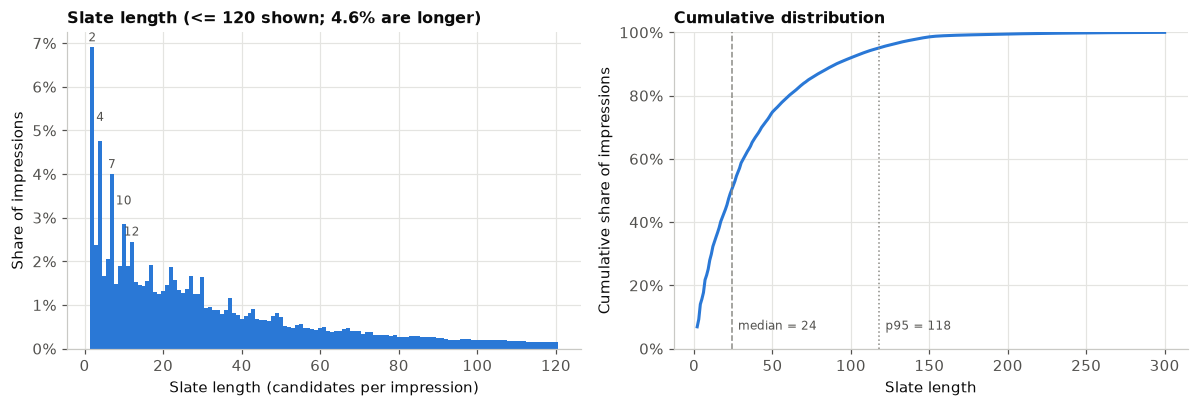

*imp_01_slate_length.png — Slate length distribution, training split (1,897,835 impressions); labels mark the five commonest lengths.*

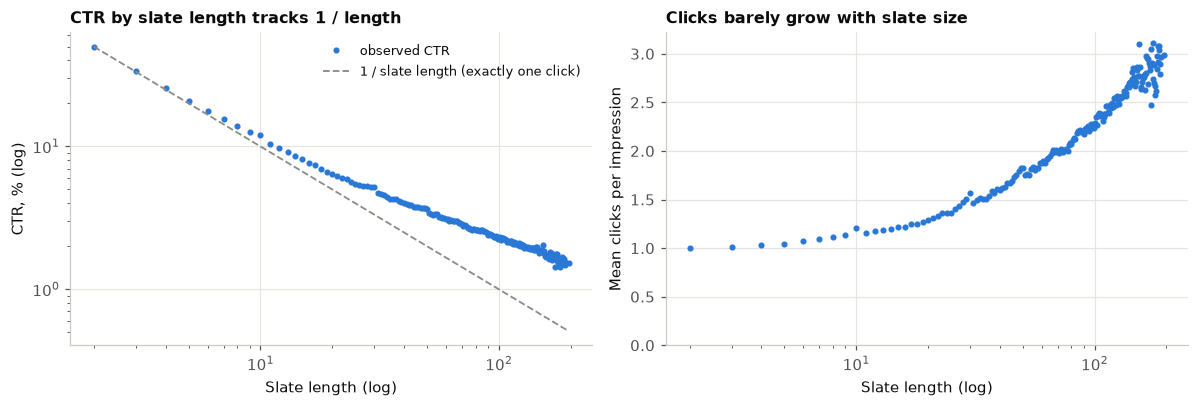

*imp_02_ctr_by_slate_length.png — Lengths with at least 200 impressions, training split.*

In [4]:
summary = pd.DataFrame([describe(imp["slate_len"], "slate_len (candidates per impression)"),
                        describe(imp["n_clicks"], "n_clicks (clicks per impression)"),
                        describe(imp["n_negatives"], "n_negatives (exposed, not clicked)"),
                        describe(imp["history_len"], "history_len (prior clicks supplied)")])
display(save_table("imp_01_impression_level_summary", summary))

dist = (imp.lazy().group_by("slate_len").agg(impressions=pl.len(), clicks=pl.col("n_clicks").cast(pl.Int64).sum())
        .with_columns(exposures=pl.col("slate_len").cast(pl.Int64) * pl.col("impressions")).sort("slate_len")
        .with_columns(impression_pct=100 * pl.col("impressions") / H["n_impressions"])
        .with_columns(cumulative_pct=pl.col("impression_pct").cum_sum(), ctr_pct=100 * pl.col("clicks") / pl.col("exposures"),
                      mean_clicks=pl.col("clicks") / pl.col("impressions"), one_click_reference_pct=100 / pl.col("slate_len")).collect())
dist_pd = save_table("imp_01_slate_length_distribution", dist)
templates = dist_pd.sort_values("impressions", ascending=False).head(8)[["slate_len", "impressions", "impression_pct"]].reset_index(drop=True)
display(save_table("imp_01_slate_length_templates", templates))
thr = [2, 5, 10, 25, 50, 100, 120, 200]
thresholds = pd.DataFrame({"slate_len_at_most": thr,
                           "impression_pct": [float(dist_pd.loc[dist_pd.slate_len <= t, "impression_pct"].sum()) for t in thr],
                           "exposure_pct": [pct(dist_pd.loc[dist_pd.slate_len <= t, "exposures"].sum(), H["n_exposures"]) for t in thr]})
display(save_table("imp_01_slate_length_thresholds", thresholds))
s = summary.set_index("statistic").iloc[0]
H.update(slate_min=int(s["min"]), slate_median=s["median"], slate_mean=s["mean"], slate_p25=s["p25"], slate_p75=s["p75"], slate_p95=s["p95"], slate_max=int(s["max"]))
tl = dict(zip(thresholds.slate_len_at_most, thresholds.impression_pct))
H.update(share_le10=tl[10], share_le25=tl[25], share_gt100=100 - tl[100], share_gt120=100 - tl[120], top_templates=templates.slate_len.head(5).tolist())

cpi = (imp.group_by("n_clicks").agg(impressions=pl.len()).sort("n_clicks")
       .with_columns(impression_pct=100 * pl.col("impressions") / H["n_impressions"]).with_columns(cumulative_pct=pl.col("impression_pct").cum_sum()))
cpi_pd = save_table("imp_02_clicks_per_impression", cpi)
H["zero_click_impressions"] = int(cpi_pd.loc[cpi_pd.n_clicks == 0, "impressions"].sum())
H["one_click_pct"] = float(cpi_pd.loc[cpi_pd.n_clicks == 1, "impression_pct"].sum())
H["two_click_pct"] = float(cpi_pd.loc[cpi_pd.n_clicks == 2, "impression_pct"].sum())
H["three_plus_pct"] = float(cpi_pd.loc[cpi_pd.n_clicks >= 3, "impression_pct"].sum())
H["mean_clicks"] = H["n_clicks"] / H["n_impressions"]
H["rho_slate_ctr"] = float(stats.spearmanr(imp["slate_len"].to_numpy(), (imp["n_clicks"] / imp["slate_len"]).to_numpy()).statistic)
sel = dist_pd[dist_pd.slate_len.isin([2, 5, 10, 25, 50, 100, 200])][["slate_len", "impressions", "mean_clicks", "ctr_pct", "one_click_reference_pct"]]
display(save_table("imp_02_ctr_by_slate_length_selected", sel))
print(f"Slates: min {H['slate_min']}, median {H['slate_median']:.0f}, mean {H['slate_mean']:.1f}, p95 {H['slate_p95']:.0f}, max {H['slate_max']} | "
      f"{H['share_le10']:.1f}% <= 10, {H['share_le25']:.1f}% <= 25, {H['share_gt100']:.1f}% > 100 | peaks at {H['top_templates']}")
print(f"Clicks per impression: zero {H['zero_click_impressions']:,}, exactly one {H['one_click_pct']:.1f}%, two {H['two_click_pct']:.1f}%, "
      f"three+ {H['three_plus_pct']:.1f}%, mean {H['mean_clicks']:.2f} | Spearman(slate_len, impression CTR) = {H['rho_slate_ctr']:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = dist_pd[dist_pd.slate_len <= 120]
axes[0].bar(d.slate_len, d.impression_pct, width=1.0, color=BLUE)
for i, L in enumerate(H["top_templates"]):
    row = dist_pd.loc[dist_pd.slate_len == L].iloc[0]
    axes[0].annotate(f"{L}", (L, row.impression_pct), textcoords="offset points", xytext=(0, 4 + 9 * (i % 2)), ha="center", fontsize=8, color=MUTED)
axes[0].set_xlabel("Slate length (candidates per impression)"); axes[0].set_ylabel("Share of impressions"); axes[0].yaxis.set_major_formatter(PCT)
axes[0].set_title(f"Slate length (<= 120 shown; {H['share_gt120']:.1f}% are longer)")
axes[1].plot(dist_pd.slate_len, dist_pd.cumulative_pct, color=BLUE, lw=2)
axes[1].axvline(H["slate_median"], color=REF, ls="--", lw=1); axes[1].text(H["slate_median"] + 4, 6, f"median = {H['slate_median']:.0f}", color=MUTED, fontsize=8)
axes[1].axvline(H["slate_p95"], color=REF, ls=":", lw=1); axes[1].text(H["slate_p95"] + 4, 6, f"p95 = {H['slate_p95']:.0f}", color=MUTED, fontsize=8)
axes[1].set_xlabel("Slate length"); axes[1].set_ylabel("Cumulative share of impressions"); axes[1].yaxis.set_major_formatter(PCT); axes[1].set_ylim(0, 100)
axes[1].set_title("Cumulative distribution")
fig.tight_layout(); save_fig(fig, "imp_01_slate_length", f"Slate length distribution, training split ({H['n_impressions']:,} impressions); labels mark the five commonest lengths.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = dist_pd[dist_pd.impressions >= 200]
axes[0].plot(d.slate_len, d.ctr_pct, "o", ms=3, color=BLUE, label="observed CTR")
axes[0].plot(d.slate_len, d.one_click_reference_pct, "--", color=REF, lw=1.2, label="1 / slate length (exactly one click)")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("Slate length (log)"); axes[0].set_ylabel("CTR, % (log)")
axes[0].set_title("CTR by slate length tracks 1 / length"); axes[0].legend()
axes[1].plot(d.slate_len, d.mean_clicks, "o", ms=3, color=BLUE)
axes[1].set_xscale("log"); axes[1].set_ylim(0, None); axes[1].set_xlabel("Slate length (log)"); axes[1].set_ylabel("Mean clicks per impression")
axes[1].set_title("Clicks barely grow with slate size")
fig.tight_layout(); save_fig(fig, "imp_02_ctr_by_slate_length", "Lengths with at least 200 impressions, training split.")

**Reading.** Slates run from 2 to 300 candidates (median 24, mean 37); the peaks at 2, 4, 7, 10 and 12 look like fixed page templates.
No impression has zero clicks: 72.5 % contain exactly one click and the mean is 1.51, so the release was filtered to impressions that
ended in a click. Because clicks barely grow with slate size, item-level CTR is close to 1 / slate length (Spearman −0.89).

**Implications.** (1) The 4.08 % overall CTR is a click-conditioned figure, not a platform CTR; it is only comparable within this log.
(2) `slate_len` predicts the label by construction and is **excluded as a feature**. (3) Ranking quality must be evaluated **per impression**
(AUC / MRR / nDCG within the slate) and never on the pooled candidate table, where slate length alone would separate labels.

## 2. Position in the slate

Position is the 1-based order of a candidate in the impression string. MIND states that this order was shuffled before release,
so the question is whether any display-rank information survives. Three views: CTR by absolute position against a null model that
uses only the slate-length mix; CTR by position with slate length held fixed; and CTR by relative position (decile of the list).

,position,exposures,clicks,ctr_pct,null_ctr_pct,observed_minus_null_pp,mean_slate_len_at_position
0,1,1897835,210899,11.1130,11.0730,0.0400,37.0500
1,2,1897835,209961,11.0630,11.0730,-0.0100,37.0500
4,5,1631372,105863,6.4890,6.5080,-0.0190,42.6360
9,10,1421094,72312,5.0880,5.0910,-0.0020,47.9110
19,20,1086821,41931,3.8580,3.8700,-0.0120,58.3710
49,50,491220,12822,2.6100,2.6160,-0.0060,90.2480
99,100,155849,3105,1.9920,1.9990,-0.0060,133.5690
199,200,10134,143,1.4110,1.4390,-0.0280,237.5360


,slate_len,impressions,mean_ctr_pct,min_ctr_pct,max_ctr_pct,range_pp,std_across_positions_pp,se_per_position_pp,chi2,df,p_value
0,7,75854,15.6342,15.4613,15.7289,0.2676,0.0891,0.1319,2.6991,6,0.8456
1,10,54051,12.1056,11.9184,12.2958,0.3774,0.1076,0.1403,5.1677,9,0.8194
2,12,46516,9.8260,9.6225,9.9987,0.3762,0.1256,0.1380,8.9555,11,0.6260
3,25,24027,5.4362,5.2066,5.7643,0.5577,0.1278,0.1463,18.0570,24,0.8002


,decile,exposures,clicks,mean_slate_len,ctr_pct,ctr_pct_slates_over_25
0,0,7779587,400149,72.8266,5.1436,2.9418
1,1,6743994,246213,78.8653,3.6508,2.9027
2,2,6849582,253622,78.5130,3.7027,2.9131
3,3,6814576,267390,78.0505,3.9238,2.9045
4,4,6531175,231188,80.2298,3.5398,2.8978
5,5,7090090,281596,76.9321,3.9717,2.9201
6,6,6985367,280313,77.1351,4.0129,2.9181
7,7,6678791,240869,79.4822,3.6065,2.8993
8,8,6914785,260572,77.9205,3.7683,2.9314
9,9,7926440,407086,72.3116,5.1358,2.9512


Pooled CTR by position 1/10/50/100: {1: 11.112609894959256, 10: 5.088474091087571, 50: 2.6102357395871505, 100: 1.9923130722686704} | largest |observed - null| over positions with >= 10k exposures: 0.27 pp
Mean slate length behind position 1: 37; behind position 100: 134


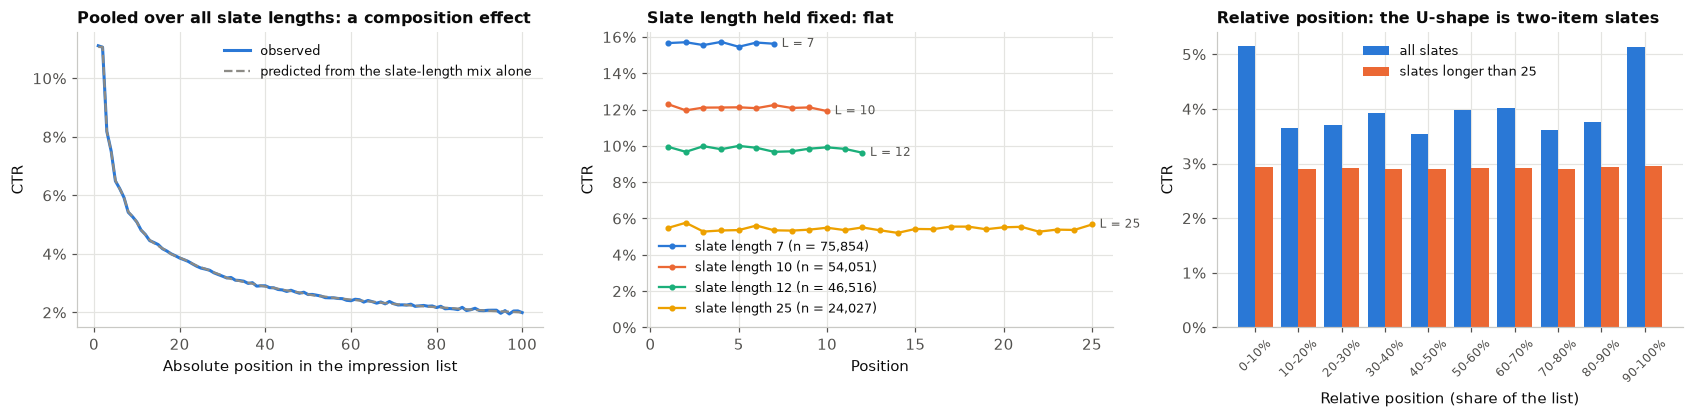

*imp_03_position.png — CTR by position in the impression list, training split.*

In [5]:
FIXED_SLATE_LENGTHS = [7, 10, 12, 25]
by_pos = (cand.lazy().group_by("position").agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum()).sort("position")
          .with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect().to_pandas())
Lmax = int(dist_pd.slate_len.max())
imps = np.zeros(Lmax + 1); clk = np.zeros(Lmax + 1)
imps[dist_pd.slate_len.values] = dist_pd.impressions.values; clk[dist_pd.slate_len.values] = dist_pd.clicks.values
Ls = np.arange(Lmax + 1, dtype=float)
clk_over_L = np.divide(clk, Ls, out=np.zeros_like(clk), where=Ls > 0)
imps_ge = np.cumsum(imps[::-1])[::-1]; num_ge = np.cumsum(clk_over_L[::-1])[::-1]; lenw_ge = np.cumsum((imps * Ls)[::-1])[::-1]
p = by_pos.position.values
assert (by_pos.exposures.values == imps_ge[p]).all()
by_pos["null_ctr_pct"] = 100 * num_ge[p] / imps_ge[p]                 # each impression's clicks spread uniformly over its own slate
by_pos["observed_minus_null_pp"] = by_pos.ctr_pct - by_pos.null_ctr_pct
by_pos["mean_slate_len_at_position"] = lenw_ge[p] / imps_ge[p]
save_table("imp_03_ctr_by_absolute_position", by_pos)
display(by_pos[by_pos.position.isin([1, 2, 5, 10, 20, 50, 100, 200])].round(3))
big = by_pos[by_pos.exposures >= 10_000]
H["max_gap_null_pp"] = float(big.observed_minus_null_pp.abs().max())
H["ctr_pos"] = {int(k): float(v) for k, v in zip(by_pos.position, by_pos.ctr_pct) if k in (1, 10, 50, 100)}
H["mean_len_pos1"] = float(by_pos.loc[by_pos.position == 1, "mean_slate_len_at_position"].iloc[0])
H["mean_len_pos100"] = float(by_pos.loc[by_pos.position == 100, "mean_slate_len_at_position"].iloc[0])

fixed = (cand.lazy().join(imp.lazy().select("impression_uid", "slate_len"), on="impression_uid")
         .filter(pl.col("slate_len").is_in(FIXED_SLATE_LENGTHS)).group_by("slate_len", "position")
         .agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum()).sort("slate_len", "position")
         .with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect().to_pandas())
save_table("imp_03_ctr_by_position_fixed_slate_length", fixed)
rows = []
for L in FIXED_SLATE_LENGTHS:
    f = fixed[fixed.slate_len == L]
    chi = stats.chisquare(f.clicks.values.astype(float))
    rows.append({"slate_len": L, "impressions": int(f.exposures.iloc[0]), "mean_ctr_pct": pct(f.clicks.sum(), f.exposures.sum()),
                 "min_ctr_pct": f.ctr_pct.min(), "max_ctr_pct": f.ctr_pct.max(), "range_pp": f.ctr_pct.max() - f.ctr_pct.min(),
                 "std_across_positions_pp": f.ctr_pct.std(ddof=0), "se_per_position_pp": 100 * np.sqrt(f.ctr_pct.mean() / 100 * (1 - f.ctr_pct.mean() / 100) / f.exposures.iloc[0]),
                 "chi2": chi.statistic, "df": L - 1, "p_value": chi.pvalue})
uniformity = pd.DataFrame(rows); display(save_table("imp_03_position_uniformity_tests", uniformity)); H["uniformity"] = uniformity.round(4).to_dict("records")

rel = (cand.lazy().join(imp.lazy().select("impression_uid", "slate_len"), on="impression_uid").select("slate_len", "position", "clicked")
       .with_columns(decile=(((pl.col("position").cast(pl.Int32) - 1) * 10) // (pl.col("slate_len").cast(pl.Int32) - 1)).clip(0, 9).cast(pl.Int8))
       .group_by("decile").agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum(), mean_slate_len=pl.col("slate_len").mean()).sort("decile")
       .with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect().to_pandas())
rel_big = (cand.lazy().join(imp.lazy().select("impression_uid", "slate_len"), on="impression_uid").filter(pl.col("slate_len") > 25).select("slate_len", "position", "clicked")
           .with_columns(decile=(((pl.col("position").cast(pl.Int32) - 1) * 10) // (pl.col("slate_len").cast(pl.Int32) - 1)).clip(0, 9).cast(pl.Int8))
           .group_by("decile").agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum()).sort("decile")
           .with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect().to_pandas())
rel["ctr_pct_slates_over_25"] = rel_big.ctr_pct.values
display(save_table("imp_03_ctr_by_relative_position_decile", rel))
H["decile_first"], H["decile_last"], H["decile_mid_min"], H["decile_mid_max"] = float(rel.ctr_pct.iloc[0]), float(rel.ctr_pct.iloc[-1]), float(rel.ctr_pct.iloc[1:-1].min()), float(rel.ctr_pct.iloc[1:-1].max())
H["decile_over25_range"] = [float(rel_big.ctr_pct.min()), float(rel_big.ctr_pct.max())]
print(f"Pooled CTR by position 1/10/50/100: {H['ctr_pos']} | largest |observed - null| over positions with >= 10k exposures: {H['max_gap_null_pp']:.2f} pp")
print(f"Mean slate length behind position 1: {H['mean_len_pos1']:.0f}; behind position 100: {H['mean_len_pos100']:.0f}")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
d = by_pos[by_pos.position <= 100]
axes[0].plot(d.position, d.ctr_pct, color=BLUE, lw=2, label="observed")
axes[0].plot(d.position, d.null_ctr_pct, color=REF, ls="--", lw=1.5, label="predicted from the slate-length mix alone")
axes[0].set_xlabel("Absolute position in the impression list"); axes[0].set_ylabel("CTR"); axes[0].yaxis.set_major_formatter(PCT)
axes[0].set_title("Pooled over all slate lengths: a composition effect"); axes[0].legend()
for L, col in zip(FIXED_SLATE_LENGTHS, SERIES):
    f = fixed[fixed.slate_len == L]
    axes[1].plot(f.position, f.ctr_pct, marker="o", ms=3, lw=1.5, color=col, label=f"slate length {L} (n = {int(f.exposures.iloc[0]):,})")
    axes[1].annotate(f"L = {L}", (f.position.iloc[-1], f.ctr_pct.iloc[-1]), textcoords="offset points", xytext=(5, 0), fontsize=8, color=MUTED, va="center")
axes[1].set_ylim(0, None); axes[1].set_xlabel("Position"); axes[1].set_ylabel("CTR"); axes[1].yaxis.set_major_formatter(PCT)
axes[1].set_title("Slate length held fixed: flat"); axes[1].legend(loc="lower left")
x = np.arange(10)
axes[2].bar(x - 0.2, rel.ctr_pct, width=0.4, color=BLUE, label="all slates")
axes[2].bar(x + 0.2, rel.ctr_pct_slates_over_25, width=0.4, color=ORANGE, label="slates longer than 25")
axes[2].set_xticks(x); axes[2].set_xticklabels([f"{i*10}-{i*10+10}%" for i in range(10)], rotation=45, fontsize=8)
axes[2].set_xlabel("Relative position (share of the list)"); axes[2].set_ylabel("CTR"); axes[2].yaxis.set_major_formatter(PCT)
axes[2].set_title("Relative position: the U-shape is two-item slates"); axes[2].legend()
fig.tight_layout(); save_fig(fig, "imp_03_position", "CTR by position in the impression list, training split.")

**Reading.** Pooled over all impressions CTR falls from 11 % at position 1 to 2 % at position 100, which looks like position bias.
It is a composition effect: short slates have a high CTR at every position and only occupy the first positions, so the exposures at
position 1 come from slates averaging 37 items and those at position 100 from slates averaging 134. A null model that spreads each
impression's clicks uniformly over its own slate reproduces the curve within 0.3 pp. With slate length held fixed the curve is flat
(7-item slates: 15.5 % to 15.7 % at every position) and a chi-square test of uniform click counts across positions is far from significant
for every length tested. The U-shape by relative position is produced by two-item slates, which land in both end deciles; it disappears
for slates longer than 25.

**Implications.** The order in `behaviors.tsv` carries **no detectable information about display rank**, consistent with the MIND
documentation that the order was shuffled. `position` is **not a feature**, no position-bias correction is needed, and no position effect
can be estimated from this log (MSN's live page very likely has one; the log cannot show it).

## 3. Exposure-to-click funnel and feedback semantics

MIND records exactly two stages: an article is exposed in a slate, and it is or is not clicked. There is no dwell time, read depth or
share signal. Labels live on (user, article) pairs inside an impression.

In [6]:
shown = cand.select(pl.col("news_code").unique())["news_code"]; clicked_art = cand.filter(pl.col("clicked") == 1).select(pl.col("news_code").unique())["news_code"]
H["n_shown"], H["n_clicked_art"] = shown.len(), clicked_art.len()
H["users_with_click"] = int(cand.filter(pl.col("clicked") == 1)["user_code"].n_unique())
H["n_imp_with_click"] = int((imp["n_clicks"] > 0).sum())
funnel = pd.DataFrame([
    ("candidate pair", "exposures (article shown to a user in a slate)", H["n_exposures"], np.nan),
    ("candidate pair", "clicks", H["n_clicks"], H["ctr_overall"]),
    ("impression", "impressions logged", H["n_impressions"], np.nan),
    ("impression", "impressions with at least one click", H["n_imp_with_click"], pct(H["n_imp_with_click"], H["n_impressions"])),
    ("article", "articles in the training news file", H["catalogue_train"], np.nan),
    ("article", "articles shown in at least one slate", H["n_shown"], pct(H["n_shown"], H["catalogue_train"])),
    ("article", "articles clicked at least once", H["n_clicked_art"], pct(H["n_clicked_art"], H["n_shown"])),
    ("user", "users with at least one impression", H["n_users"], np.nan),
    ("user", "users with at least one click", H["users_with_click"], pct(H["users_with_click"], H["n_users"]))],
    columns=["level", "stage", "count", "share_of_previous_stage_pct"])
display(save_table("imp_04_funnel", funnel))

hist_full = pl.read_parquet(PROCESSED / f"impressions_{SPLIT}.parquet", columns=["impression_uid", "user_code", "history", "history_len"])
H["history_entries_once_per_user"] = int(hist_full.unique(subset=["user_code"], keep="first")["history_len"].cast(pl.Int64).sum())
H["pairs_unobserved_approx"] = H["n_users"] * H["catalogue_train"] - H["n_exposures"] - H["history_entries_once_per_user"]
pairs = pd.DataFrame([
    ("shown in a slate and clicked", H["n_clicks"], "positive, y = 1", "target"),
    ("shown in a slate, not clicked", H["n_negatives"], "explicit negative, y = 0", "target"),
    ("in the user's supplied history", H["history_entries_once_per_user"], "past positive (clicked before the log window)", "input only, via the user profile"),
    ("neither shown nor in history", H["pairs_unobserved_approx"], "unobserved: label unknown, not zero", "none (never a negative)")],
    columns=["(user, article) pair", "count", "meaning", "role in the model"])
display(save_table("imp_04_pair_classification", pairs))
print(f"Articles never a candidate in the window: {H['catalogue_train'] - H['n_shown']:,} of {H['catalogue_train']:,} (they appear only in histories)")

,level,stage,count,share_of_previous_stage_pct
0,candidate pair,exposures (article shown to a user in a slate),70314387,NaN
1,candidate pair,clicks,2868998,4.0802
2,impression,impressions logged,1897835,NaN
3,impression,impressions with at least one click,1897835,100.0000
4,article,articles in the training news file,98671,NaN
5,article,articles shown in at least one slate,24641,24.9729
6,article,articles clicked at least once,15292,62.0592
7,user,users with at least one impression,667880,NaN
8,user,users with at least one click,667880,100.0000


,"(user, article) pair",count,meaning,role in the model
0,shown in a slate and clicked,2868998,"positive, y = 1",target
1,"shown in a slate, not clicked",67445389,"explicit negative, y = 0",target
2,in the user's supplied history,12874380,past positive (clicked before the log window),"input only, via the user profile"
3,neither shown nor in history,65817198713,"unobserved: label unknown, not zero",none (never a negative)


Articles never a candidate in the window: 74,030 of 98,671 (they appear only in histories)


**Reading.** At the pair level 70.3 M exposures produce 2.87 M clicks (4.08 %). At the impression and user levels the conversion is 100 %
by construction of the release. At the article level, 98,671 articles in the training news file narrow to 24,641 ever shown and 15,292 ever
clicked: the slates were assembled by MSN's own candidate generation before the data was written, and the log carries labels only for the
articles MSN chose to show.

**Implications.** A clicked candidate is the positive class; an exposed-but-unclicked candidate is an explicit negative; a history
article is a past positive that enters only through the user profile; every other pair is **unobserved, not negative**. The re-ranking
stage can be trained directly on logged slates. The candidate-generation stage retrieves from the full catalogue but can only be
*scored* against known clicks (Recall@M), so full-catalogue metrics are conservative lower bounds; within-impression metrics stay the clean
measure of ranking quality.

## 4. Label imbalance and negative sampling

The team's decision (3 Oct 2026): for each clicked article, draw K = 4 unclicked articles from the same impression, at random without
replacement, in one seeded draw reused for every epoch and every model; validation and test slates stay complete. The table shows what
that costs for other K as well.

,measure,value
0,"explicit negatives per positive, pooled",23.5083
1,"negatives per positive, median impression",16.2000
2,"negatives per positive, p25 / p75 impression",6.5 / 34.0
3,impressions with fewer than 4 explicit negativ...,14.1197
4,impressions with zero explicit negatives (%),0.0000


,K,training_rows,negatives_per_positive_trained_on,explicit_negatives_never_used_pct_lower_bound,positives_in_impressions_with_fewer_than_K_negatives_pct
0,4,2868998,3.7605,84.0037,9.5171
1,8,2868998,6.9834,70.2938,16.5350
2,16,2868998,11.8444,49.6163,28.5530
3,24,2868998,15.1064,35.7401,39.2147
4,32,2868998,17.3024,26.3988,49.0929
5,all,2868998,23.5083,0.0000,0.0000


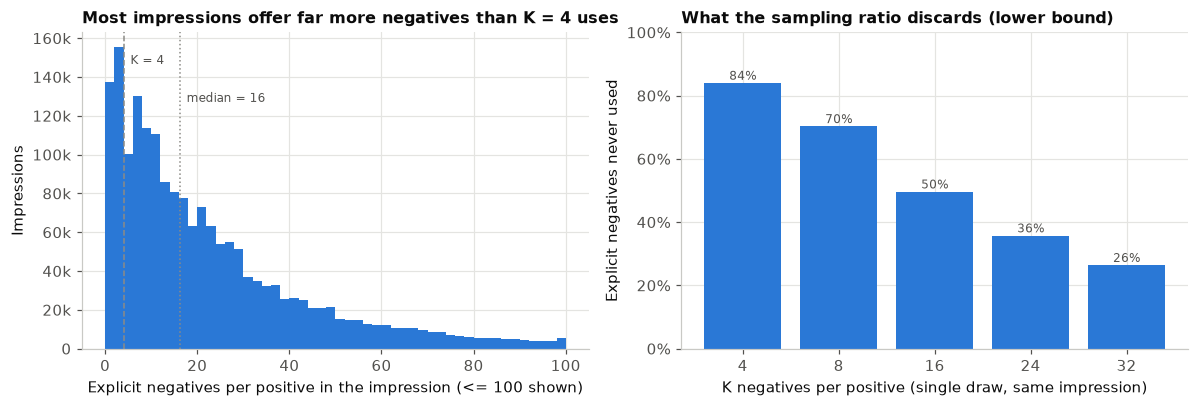

*imp_04_negative_sampling.png — Negatives per positive and the cost of the sampling ratio K, training split.*

In [7]:
NEG_K = 4
ratio = (imp["n_negatives"] / imp["n_clicks"])
P_, N_ = H["n_clicks"], H["n_negatives"]
H["neg_ratio_pooled"], H["neg_ratio_median"] = N_ / P_, float(ratio.median())
H["share_imp_lt_k"] = 100 * float((imp["n_negatives"] < NEG_K).mean())
negatives = pd.DataFrame([("explicit negatives per positive, pooled", N_ / P_), ("negatives per positive, median impression", float(ratio.median())),
                          ("negatives per positive, p25 / p75 impression", f"{float(ratio.quantile(0.25)):.1f} / {float(ratio.quantile(0.75)):.1f}"),
                          (f"impressions with fewer than {NEG_K} explicit negatives (%)", H["share_imp_lt_k"]),
                          ("impressions with zero explicit negatives (%)", 100 * float((imp["n_negatives"] == 0).mean()))], columns=["measure", "value"])
display(save_table("imp_05_negatives_per_positive", negatives))
sweep = []
for K_ in [4, 8, 16, 24, 32]:
    cap = int(imp.select(pl.min_horizontal(pl.col("n_negatives").cast(pl.Int64), K_ * pl.col("n_clicks").cast(pl.Int64)).sum()).item())
    pos_short = int(imp.filter(pl.col("n_negatives") < K_)["n_clicks"].cast(pl.Int64).sum())
    sweep.append({"K": K_, "training_rows": P_, "negatives_per_positive_trained_on": cap / P_, "explicit_negatives_never_used_pct_lower_bound": 100 * (1 - cap / N_),
                  "positives_in_impressions_with_fewer_than_K_negatives_pct": 100 * pos_short / P_})
sweep.append({"K": "all", "training_rows": P_, "negatives_per_positive_trained_on": N_ / P_, "explicit_negatives_never_used_pct_lower_bound": 0.0, "positives_in_impressions_with_fewer_than_K_negatives_pct": 0.0})
sweep = pd.DataFrame(sweep); display(save_table("imp_05_negative_sampling_k_sweep", sweep)); H["k_sweep"] = sweep.round(3).to_dict("records")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
r = ratio.to_numpy(); r = r[r <= 100]
axes[0].hist(r, bins=np.arange(0, 101, 2), color=BLUE)
axes[0].axvline(NEG_K, color=REF, ls="--", lw=1); axes[0].text(NEG_K + 1.5, axes[0].get_ylim()[1] * 0.9, f"K = {NEG_K}", color=MUTED, fontsize=8)
axes[0].axvline(H["neg_ratio_median"], color=REF, ls=":", lw=1); axes[0].text(H["neg_ratio_median"] + 1.5, axes[0].get_ylim()[1] * 0.78, f"median = {H['neg_ratio_median']:.0f}", color=MUTED, fontsize=8)
axes[0].set_xlabel("Explicit negatives per positive in the impression (<= 100 shown)"); axes[0].set_ylabel("Impressions"); axes[0].yaxis.set_major_formatter(THOUSANDS)
axes[0].set_title("Most impressions offer far more negatives than K = 4 uses")
sw = sweep[sweep.K != "all"]
axes[1].bar(sw.K.astype(str), sw.explicit_negatives_never_used_pct_lower_bound, color=BLUE)
for xk, v in zip(sw.K.astype(str), sw.explicit_negatives_never_used_pct_lower_bound):
    axes[1].text(xk, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=MUTED)
axes[1].set_xlabel("K negatives per positive (single draw, same impression)"); axes[1].set_ylabel("Explicit negatives never used"); axes[1].yaxis.set_major_formatter(PCT)
axes[1].set_ylim(0, 100); axes[1].set_title("What the sampling ratio discards (lower bound)")
fig.tight_layout(); save_fig(fig, "imp_04_negative_sampling", "Negatives per positive and the cost of the sampling ratio K, training split.")

**Reading.** There are 23.5 explicit negatives per positive overall and 16 in the median impression; 14 % of impressions contain fewer than
4 negatives. With K = 4 at least 84 % of the explicit negatives never enter training and 9.5 % of positives sit in impressions with fewer
than 4 negatives (for those every available negative is kept; none is duplicated).

**Implications.** Report the discarded share with every trained model; run K = 8 and K = 16 as a sensitivity check (unused share 70 % and
50 % at the same number of training rows, 2,868,998). Exposed negatives are the right negatives for the re-ranker: they passed the same
editorial and freshness filter as the positives and are the only pairs with an observed label. Sampled catalogue negatives are a training
device for the retrieval stage only, under the stated assumption that most unobserved pairs would not have been clicked.

## 5. Repeat exposure and history overlap

Two checks on how much an explicit negative means beyond the impression it came from: what happens when the same user is shown the same
article again, and how often a candidate is already in the user's supplied history.

,exposure_rank,clicked_earlier,exposures,clicks,ctr_pct,share_of_exposures_pct
0,1st,n/a,60309926,2614241,4.3347,85.7718
1,2nd,no,7359035,192664,2.6181,10.4659
2,2nd,yes,320271,16470,5.1425,0.4555
3,3rd or later,no,2153071,39790,1.8481,3.0621
4,3rd or later,yes,172084,5833,3.3896,0.2447


,measure,count,denominator,pct
0,candidates already in the user's history,200053,70314387,0.2845
1,clicked candidates already in the user's history,16737,2868998,0.5834
2,CTR of candidates already in the history (%),16737,200053,8.3663
3,impressions with at least one such candidate,148629,1897835,7.8315


Repeat exposures: 10,004,461 (14.23% of exposures) · computed in 14 s


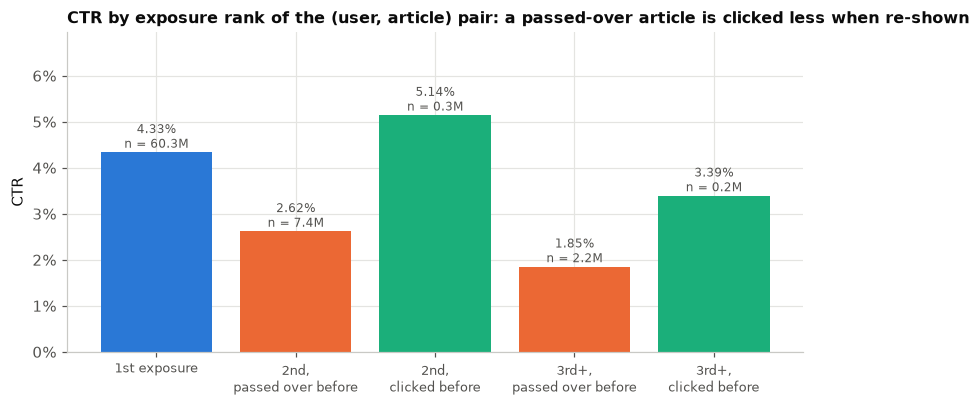

*imp_05_repeat_exposure.png — Repeat exposure within the training window.*

In [8]:
t0 = time.time()
pair_key = pl.col("user_code").cast(pl.Int64) * 1_000_000 + pl.col("news_code").cast(pl.Int64)
rep = (cand.select("impression_uid", "timestamp", "clicked", pair_key.alias("pair_key")).filter(pl.col("pair_key").is_duplicated())
       .sort(["pair_key", "timestamp", "impression_uid"])
       .with_columns(exposure_rank=pl.col("clicked").cum_count().over("pair_key").cast(pl.Int16),
                     prior_clicks=pl.col("clicked").cast(pl.Int32).cum_sum().over("pair_key") - pl.col("clicked"))
       .filter(pl.col("exposure_rank") >= 2))
n_repeat = rep.height
rk = (rep.group_by(pl.when(pl.col("exposure_rank") >= 3).then(pl.lit("3rd or later")).otherwise(pl.lit("2nd")).alias("exposure_rank"),
                   pl.when(pl.col("prior_clicks") > 0).then(pl.lit("yes")).otherwise(pl.lit("no")).alias("clicked_earlier"))
      .agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum()).sort("exposure_rank", "clicked_earlier").to_pandas())
first = pd.DataFrame([{"exposure_rank": "1st", "clicked_earlier": "n/a", "exposures": H["n_exposures"] - n_repeat, "clicks": H["n_clicks"] - int(rk.clicks.sum())}])
repeat_tbl = pd.concat([first, rk], ignore_index=True)
repeat_tbl["ctr_pct"] = 100 * repeat_tbl.clicks / repeat_tbl.exposures; repeat_tbl["share_of_exposures_pct"] = 100 * repeat_tbl.exposures / H["n_exposures"]
display(save_table("imp_06_repeat_exposure", repeat_tbl))
rep_no, rep_yes = rk[rk.clicked_earlier == "no"], rk[rk.clicked_earlier == "yes"]
H.update(repeat_share=100 * n_repeat / H["n_exposures"], ctr_first=float(repeat_tbl.ctr_pct.iloc[0]),
         ctr_repeat_not_clicked=pct(rep_no.clicks.sum(), rep_no.exposures.sum()), ctr_repeat_clicked=pct(rep_yes.clicks.sum(), rep_yes.exposures.sum()),
         repeat_not_clicked_share=100 * rep_no.exposures.sum() / H["n_exposures"], repeat_table=repeat_tbl.round(3).to_dict("records"))
del rep

hist_codes = hist_full.select("impression_uid", h=pl.col("history").fill_null("").str.split(" ").list.eval(pl.element().filter(pl.element() != "").str.strip_prefix("N").cast(pl.Int32)))
slate_lists = cand.group_by("impression_uid").agg(c=pl.col("news_code"), p=pl.col("news_code").filter(pl.col("clicked") == 1))
ov = (slate_lists.join(hist_codes, on="impression_uid")
      .select(n_cand=pl.col("c").list.set_intersection("h").list.len(), n_pos=pl.col("p").list.set_intersection("h").list.len(),
              slate_len=pl.col("c").list.len(), n_clicks=pl.col("p").list.len())
      .select(pl.col("n_cand").sum().alias("cand_in_hist"), pl.col("n_pos").sum().alias("clicks_in_hist"), (pl.col("n_cand") > 0).sum().alias("imps_with_overlap"),
              pl.col("slate_len").sum().alias("cands"), pl.col("n_clicks").sum().alias("clicks"), pl.len().alias("imps")).row(0, named=True))
overlap = pd.DataFrame([("candidates already in the user's history", ov["cand_in_hist"], ov["cands"], pct(ov["cand_in_hist"], ov["cands"])),
                        ("clicked candidates already in the user's history", ov["clicks_in_hist"], ov["clicks"], pct(ov["clicks_in_hist"], ov["clicks"])),
                        ("CTR of candidates already in the history (%)", ov["clicks_in_hist"], ov["cand_in_hist"], pct(ov["clicks_in_hist"], ov["cand_in_hist"])),
                        ("impressions with at least one such candidate", ov["imps_with_overlap"], ov["imps"], pct(ov["imps_with_overlap"], ov["imps"]))],
                       columns=["measure", "count", "denominator", "pct"])
display(save_table("imp_06_history_overlap", overlap))
H.update(hist_cand_pct=overlap.pct.iloc[0], hist_click_pct=overlap.pct.iloc[1], hist_ctr=overlap.pct.iloc[2], hist_imp_pct=overlap.pct.iloc[3])
del slate_lists, hist_codes
print(f"Repeat exposures: {n_repeat:,} ({H['repeat_share']:.2f}% of exposures) · computed in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
labels = ["1st exposure", "2nd,\npassed over before", "2nd,\nclicked before", "3rd+,\npassed over before", "3rd+,\nclicked before"]
order = [("1st", "n/a"), ("2nd", "no"), ("2nd", "yes"), ("3rd or later", "no"), ("3rd or later", "yes")]
vals = [float(repeat_tbl[(repeat_tbl.exposure_rank == a) & (repeat_tbl.clicked_earlier == b)].ctr_pct.iloc[0]) for a, b in order]
ns = [int(repeat_tbl[(repeat_tbl.exposure_rank == a) & (repeat_tbl.clicked_earlier == b)].exposures.iloc[0]) for a, b in order]
cols = [BLUE, ORANGE, AQUA, ORANGE, AQUA]
bars = ax.bar(range(5), vals, color=cols)
for i, (v, n) in enumerate(zip(vals, ns)):
    ax.text(i, v + 0.1, f"{v:.2f}%\nn = {n/1e6:.1f}M", ha="center", fontsize=8, color=MUTED)
ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=8.5); ax.set_ylabel("CTR"); ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, max(vals) * 1.35)
ax.set_title("CTR by exposure rank of the (user, article) pair: a passed-over article is clicked less when re-shown")
fig.tight_layout(); save_fig(fig, "imp_05_repeat_exposure", "Repeat exposure within the training window.")

**Reading.** 14 % of exposures re-show an article the same user has already seen in the window, and 13.5 % of all exposures are articles
the user passed over before. CTR is 4.3 % on first exposure, 2.6 % on a second exposure after a pass and 5.1 % after a click; third or later
exposures fall further (1.9 % and 3.4 %). Candidates already in the supplied history are rare (0.3 % of candidates, 0.6 % of clicks, 8 % of
impressions contain one) and are clicked at 8.4 % when re-shown.

**Implications.** An explicit negative carries information beyond its own impression: **"previously shown and not clicked" is a usable,
time-causal feature** (`prior_exposure_count` with its outcome). History overlap is too small to be leakage; the rows are kept.

## 6. Slate composition: category diversity, stand-out articles and crowding

Does the make-up of the slate change how users click? Two naive patterns look strong (diverse slates get more clicks; an article that is the
only one of its category gets a huge CTR). Both have to be checked at fixed slate size, because larger slates mechanically collect more clicks and
lower per-article CTR. Categories come from the training news file.

,n_cats_plot,slates,mean_size,mean_clicks,clicks,exposures,ctr_pct
0,1,42916,3.0392,1.0182,43697,130432,33.5017
1,2,147567,2.7705,1.0118,149304,408831,36.5197
2,3,108093,5.1216,1.0526,113776,553612,20.5516
3,4,115451,7.5207,1.1012,127140,868276,14.6428
4,5,105672,10.1410,1.1491,121425,1071620,11.3310
5,6,86559,13.5626,1.2077,104535,1173969,8.9044
6,7,102627,17.1744,1.2592,129231,1762554,7.3320
7,8,125312,22.8807,1.3455,168611,2867230,5.8806
8,9,144035,30.6506,1.4537,209383,4414765,4.7428
9,10,184453,37.8812,1.5636,288416,6987294,4.1277


,slate_len,n_cats_plot,slates,mean_clicks,clicks,ctr_pct
0,10,2,667,1.1904,794,11.9040
1,10,3,1963,1.1921,2340,11.9205
2,10,4,5112,1.1913,6090,11.9131
3,10,5,14475,1.1993,17360,11.9931
4,10,6,14628,1.2127,17740,12.1274
5,10,7,11977,1.2221,14637,12.2209
6,10,8,4540,1.2370,5616,12.3700
7,10,9,621,1.2544,779,12.5443
8,20,4,207,1.2367,256,6.1836
9,20,5,424,1.2759,541,6.3797


slate_len,10,20,30,50
n_cats_plot,,,,
2,1.1900,NaN,NaN,NaN
3,1.1900,NaN,NaN,NaN
4,1.1900,1.2400,NaN,NaN
5,1.2000,1.2800,1.5000,NaN
6,1.2100,1.2500,1.5400,NaN
7,1.2200,1.3200,1.5300,NaN
8,1.2400,1.3000,1.5800,1.8700
9,1.2500,1.2800,1.5700,1.8900
10,NaN,1.2900,1.5900,1.8600


,k_bin,category_slates,clicks,exposures,mean_category_clicks,per_article_ctr_pct
0,1,5415566,506896,5415566,0.0936,9.3600
1,2,2848729,374274,5697458,0.1314,6.5691
2,3,1817227,280847,5451681,0.1545,5.1516
3,4,1281902,236299,5127608,0.1843,4.6084
4,5+,4565239,1470682,48622074,0.3221,3.0247


,role,exposures,clicks,ctr_pct,size_band
0,majority category,21725955,972530,4.4764,all slates
1,shared minority,43042434,1345875,3.1269,all slates
2,unique category,5415566,506896,9.3600,all slates
3,unique category,28364,921,3.2471,slate length 50
4,majority category,103642,2642,2.5492,slate length 100
5,majority category,204345,10901,5.3346,slate length 25
6,shared minority,247301,5374,2.1731,slate length 100
7,shared minority,450871,16037,3.5569,slate length 50
8,shared minority,87640,10471,11.9477,slate length 10
9,majority category,202865,7895,3.8918,slate length 50


Slate composition computed in 15 s · mean categories per slate 8.4


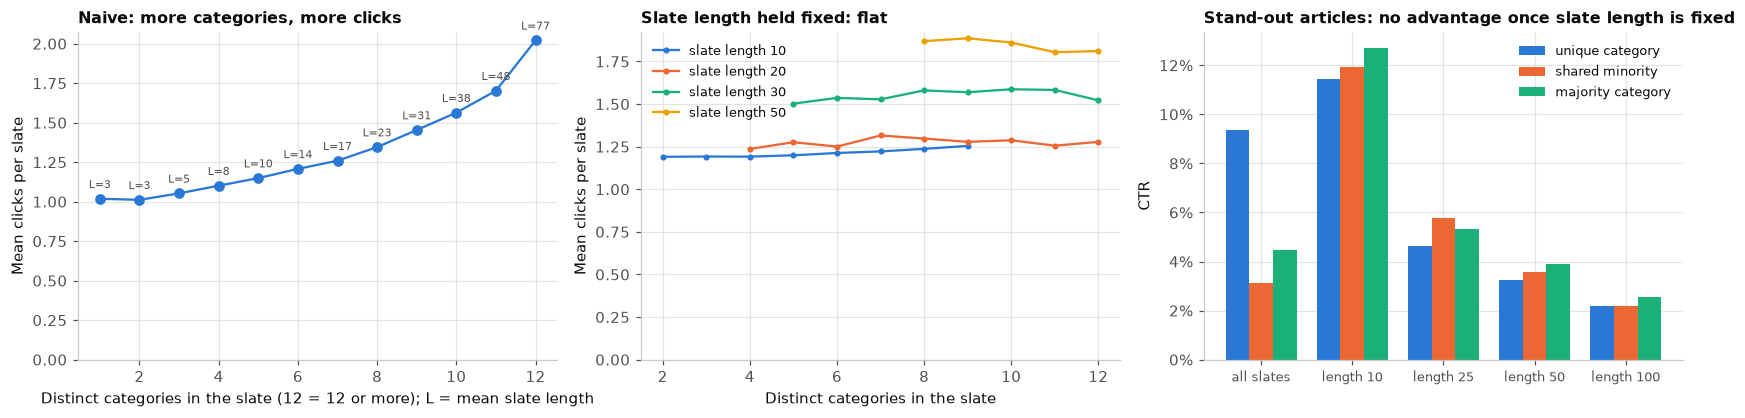

*imp_06_slate_composition.png — Category diversity and stand-out articles, training split.*

In [9]:
t0 = time.time()
cat_map = news.select("news_code", pl.col("category").cast(pl.Categorical))
cc = (cand.lazy().join(cat_map.lazy(), on="news_code", how="left").join(imp.lazy().select("impression_uid", "slate_len"), on="impression_uid")
      .select("impression_uid", "slate_len", "category", "clicked"))
slate_cat = cc.group_by("impression_uid", "category").agg(k=pl.len(), cat_clicks=pl.col("clicked").cast(pl.Int32).sum(), slate_len=pl.col("slate_len").first())
slate_div = (slate_cat.with_columns(p=pl.col("k") / pl.col("slate_len")).group_by("impression_uid")
             .agg(n_cats=pl.len(), entropy=(-(pl.col("p") * pl.col("p").log())).sum(), top_share=pl.col("p").max(), slate_len=pl.col("slate_len").first(),
                  n_clicks=pl.col("cat_clicks").sum())
             .with_columns(norm_entropy=pl.when(pl.col("n_cats") > 1).then(pl.col("entropy") / pl.col("n_cats").cast(pl.Float64).log()).otherwise(0.0)).collect())
H["mean_categories_per_slate"] = float(slate_div["n_cats"].mean())

naive = (slate_div.with_columns(n_cats_plot=pl.min_horizontal(pl.col("n_cats"), pl.lit(12))).group_by("n_cats_plot")
         .agg(slates=pl.len(), mean_size=pl.col("slate_len").mean(), mean_clicks=pl.col("n_clicks").mean(),
              clicks=pl.col("n_clicks").cast(pl.Int64).sum(), exposures=pl.col("slate_len").cast(pl.Int64).sum())
         .with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).sort("n_cats_plot").to_pandas())
display(save_table("imp_07_diversity_naive", naive))
SIZES = [10, 20, 30, 50]
fixed_div = (slate_div.filter(pl.col("slate_len").is_in(SIZES)).with_columns(n_cats_plot=pl.min_horizontal(pl.col("n_cats"), pl.lit(12)))
             .group_by("slate_len", "n_cats_plot").agg(slates=pl.len(), mean_clicks=pl.col("n_clicks").mean(), clicks=pl.col("n_clicks").cast(pl.Int64).sum())
             .with_columns(ctr_pct=100 * pl.col("clicks") / (pl.col("slates") * pl.col("slate_len"))).filter(pl.col("slates") >= 200).sort("slate_len", "n_cats_plot").to_pandas())
display(save_table("imp_07_diversity_fixed_size", fixed_div))
display(fixed_div.pivot(index="n_cats_plot", columns="slate_len", values="mean_clicks").round(2))

# stand-out (unique-category) articles and crowding
crowd = (slate_cat.with_columns(k_bin=bucket("k", [1, 2, 3, 4], ["1", "2", "3", "4", "5+"])).group_by("k_bin")
         .agg(category_slates=pl.len(), clicks=pl.col("cat_clicks").cast(pl.Int64).sum(), exposures=pl.col("k").cast(pl.Int64).sum(), mean_category_clicks=pl.col("cat_clicks").mean())
         .with_columns(per_article_ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect())
crowd = ordered(crowd, "k_bin", ["1", "2", "3", "4", "5+"]); display(save_table("imp_07_crowding", crowd))
STANDOUT_SIZES = [10, 25, 50, 100]
role = (slate_cat.join(slate_div.lazy().select("impression_uid", "n_cats", "top_share"), on="impression_uid").filter(pl.col("n_cats") > 1)
        .with_columns(role=pl.when(pl.col("k") == 1).then(pl.lit("unique category")).when(pl.col("k") / pl.col("slate_len") >= pl.col("top_share")).then(pl.lit("majority category")).otherwise(pl.lit("shared minority")),
                      size_band=pl.when(pl.col("slate_len").is_in(STANDOUT_SIZES)).then(pl.lit("slate length ") + pl.col("slate_len").cast(pl.Utf8)).otherwise(pl.lit("other")))
        .group_by("size_band", "role").agg(exposures=pl.col("k").cast(pl.Int64).sum(), clicks=pl.col("cat_clicks").cast(pl.Int64).sum())
        .with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect().to_pandas())
role_all = role.groupby("role")[["exposures", "clicks"]].sum().reset_index(); role_all["ctr_pct"] = 100 * role_all.clicks / role_all.exposures; role_all["size_band"] = "all slates"
role = pd.concat([role_all, role[role.size_band != "other"]], ignore_index=True)
ROLE_ORDER, BAND_ORDER = ["unique category", "shared minority", "majority category"], ["all slates"] + [f"slate length {L}" for L in STANDOUT_SIZES]
display(save_table("imp_07_standout_by_size_band", role))
H["standout"] = role.pivot(index="size_band", columns="role", values="ctr_pct").reindex(BAND_ORDER)[ROLE_ORDER].round(2).to_dict("index")
print(f"Slate composition computed in {time.time() - t0:.0f} s · mean categories per slate {H['mean_categories_per_slate']:.1f}")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
axes[0].plot(naive.n_cats_plot, naive.mean_clicks, marker="o", color=BLUE, label="mean clicks per slate")
for xk, ms in zip(naive.n_cats_plot, naive.mean_size):
    axes[0].annotate(f"L={ms:.0f}", (xk, naive.loc[naive.n_cats_plot == xk, "mean_clicks"].iloc[0]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7, color=MUTED)
axes[0].set_xlabel("Distinct categories in the slate (12 = 12 or more); L = mean slate length"); axes[0].set_ylabel("Mean clicks per slate"); axes[0].set_ylim(0, None)
axes[0].set_title("Naive: more categories, more clicks")
for L, col in zip(SIZES, SERIES):
    d = fixed_div[fixed_div.slate_len == L]
    axes[1].plot(d.n_cats_plot, d.mean_clicks, marker="o", ms=3, color=col, label=f"slate length {L}")
axes[1].set_xlabel("Distinct categories in the slate"); axes[1].set_ylabel("Mean clicks per slate"); axes[1].set_ylim(0, None)
axes[1].set_title("Slate length held fixed: flat"); axes[1].legend()
piv = role.pivot(index="size_band", columns="role", values="ctr_pct").reindex(BAND_ORDER)[ROLE_ORDER]
x = np.arange(len(BAND_ORDER)); w = 0.26
for i, (r_, col) in enumerate(zip(ROLE_ORDER, SERIES)):
    axes[2].bar(x + (i - 1) * w, piv[r_], width=w, color=col, label=r_)
axes[2].set_xticks(x); axes[2].set_xticklabels([b.replace("slate length ", "length ") for b in BAND_ORDER], fontsize=8.5); axes[2].set_ylabel("CTR"); axes[2].yaxis.set_major_formatter(PCT)
axes[2].set_title("Stand-out articles: no advantage once slate length is fixed"); axes[2].legend()
fig.tight_layout(); save_fig(fig, "imp_06_slate_composition", "Category diversity and stand-out articles, training split.")
del slate_div, cc, slate_cat

**Reading.** Diverse slates collect more clicks only because they are longer: at a fixed slate length (10, 20, 30 or 50 items) mean clicks
and CTR are flat across 1 to 12 categories. An article that is the only one of its category looks spectacular in the pooled view, but
singletons live in short slates. At a fixed slate length the advantage disappears and even reverses: at length 10 a singleton-category article is
clicked at 11.5 % against 12.7 % for majority-category articles, at length 50 3.3 % against 3.9 %. The crowding table shows why the pooled view
misleads: when k candidates share a category, the category wins more clicks in total but each article's CTR falls roughly as 1 / k, and small k
occurs in small slates.

**Implications.** Slate-level diversity and "stand-out" indicators carry little independent signal; they are low-priority features. The
within-slate share of the candidate's category (`cat_count / slate_len`) is a cheap slate-context feature worth one ablation, with the caveat
that the whole log is conditioned on a click, so we cannot see whether a diverse slate converts a non-clicking visit.

## 7. What this notebook decides

| Finding | Evidence | Decision |
|---|---|---|
| Every impression has a click; CTR ≈ 1 / slate length | §1, Spearman −0.89 | `slate_len` excluded; per-impression metrics; CTR is a within-log yardstick |
| Position carries no display-rank information | §2, null model within 0.3 pp, chi-square p > 0.6 | `position` excluded; no position-bias correction; no position effect claimed |
| Labels exist only for shown pairs; 75 % of the news file is never a candidate | §3 | unobserved ≠ negative; retrieval scored against known clicks only; within-impression metrics are the clean measure |
| 23.5 negatives per positive; K = 4 discards ≥ 84 % | §4 | keep K = 4 single seeded draw; report the discarded share; K = 8 / 16 sensitivity |
| Re-shown passed-over articles are clicked less (2.6 % vs 4.3 %) | §5 | build `prior_exposure_count` / previous-outcome features time-causally |
| History overlap 0.3 % of candidates | §5 | keep rows; no leakage concern |
| Diversity and stand-out effects vanish at fixed size | §6 | slate-context features low priority; one ablation on category share |

In [10]:
manifest["tables"] = sorted(set(manifest["tables"])); manifest["figures"] = sorted(set(manifest["figures"]))
(EDA_DIR / f"manifest_{NOTEBOOK_NAME}.json").write_text(json.dumps(manifest, indent=2, default=str))
print(f"{len(manifest['figures'])} figures in {FIG_DIR}\n{len(manifest['tables'])} tables in {TABLE_DIR}\nheadline numbers -> manifest_{NOTEBOOK_NAME}.json")

6 figures in /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/figures
20 tables in /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/tables
headline numbers -> manifest_impression_analysis.json
